In [ ]:
# 整理后的R包加载与配置

# 基础分析包
suppressMessages(library(Seurat))
suppressMessages(library(Signac))
suppressMessages(library(dplyr))
suppressMessages(library(ggplot2))
suppressMessages(library(future))
suppressMessages(library(parallel))
# suppressMessages(library(Nebulosa))
suppressMessages(library(RColorBrewer))
suppressMessages(library(viridis))
suppressMessages(library(qs))

# 多组学/转录因子包
suppressMessages(library(scMEGA))
suppressMessages(library(Pando))
suppressMessages(library(harmony))

# motif 分析等
# suppressMessages(library(JASPAR2020))
suppressMessages(library(TFBSTools))
suppressMessages(library(chromVAR))
suppressMessages(library(motifmatchr))

# 可视化
suppressMessages(library(igraph))
suppressMessages(library(ggraph))

# 基因组分析
suppressMessages(library(GenomicRanges))
suppressMessages(library(BSgenome))
suppressMessages(library(Rsamtools))  # FaFile
suppressMessages(library(ChIPseeker))
suppressMessages(library(GenomicFeatures))
suppressMessages(library(rtracklayer)) # 读写 BED/GFF
suppressMessages(library(txdbmaker))
library(GenomeInfoDb)


# TxDb
# Python 环境
suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/betz_snRNA_snATAC/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/betz_snRNA_snATAC/.venv")

# 资源设定
plan("multicore", workers = 128)
options(future.globals.maxSize = 100000 * 1024^5)

# 加载 genome 注释
load('/home/chaiqw/project/macaque_motor_new/macFas5_genomeInfo_signac.RData')


In [2]:
obj = readRDS('/home/chaiqw/project/betz_anal_new/coembed_5000feature-new05.rds')
obj

An object of class Seurat 
743645 features across 4641 samples within 3 assays 
Active assay: RNA (23306 features, 10000 variable features)
 5 layers present: data.1, data.2, counts.1, scale.data.1, scale.data
 2 other assays present: peaks, GeneActivity
 3 dimensional reductions calculated: pca, harmony, umap

In [ ]:
obj$ET_class <- ifelse(obj$seurat_clusters == 2, "Betz cells", "other L5_ET-neuron")
saveRDS(obj, '/home/chaiqw/project/betz_anal_new/RNA_ATAC_L5ET_combined.rds')

In [6]:
sub_atac = subset(obj, tech == 'ATAC')
sub_atac$ET_class <- ifelse(sub_atac$seurat_clusters == 2, "Betz cells", "other L5_ET-neuron")

In [47]:
peak_obj = readRDS('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak-20251106-new.rds')
peak_obj

An object of class Seurat 
741246 features across 928 samples within 3 assays 
Active assay: peaks (699368 features, 664763 variable features)
 2 layers present: counts, data
 2 other assays present: GeneActivity, RNA
 4 dimensional reductions calculated: pca, umap, harmony, umap_harmony

In [ ]:
# obj_atac = subset(obj, tech == 'ATAC')
# obj_rna = subset(obj, tech == 'RNA')

In [ ]:
txdb_test <- makeTxDbFromGFF("/mnt/112-rawdata-112/macaque/snRNA/motor_cortex/Macaca_fascicularis_5.0.91.2.2/Macaca_fascicularis_5.0.91.2.2_withchrname.gtf", format = "gtf") 
peaks_gr <- granges(sub_atac@assays$peaks)


peak_anno <- annotatePeak(
  peaks_gr,
  TxDb = txdb_test,
  tssRegion = c(-3000, 3000),   # promoter 定义，可按需改（常用 -2kb ~ +500bp）
  verbose = FALSE
)

anno_df <- as.data.frame(peak_anno@anno)
anno_df1 = anno_df
anno_df1$peak = paste0(anno_df1$seqnames, '-', anno_df1$start, '-', anno_df1$end)

links <- Links(peak_obj)
links_df <- as.data.frame(links)

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”
OK



>> Update txdb in cache...
>> Using Genome: NA ...
>> Using Genome: NA ...
>> Using Genome: NA ...


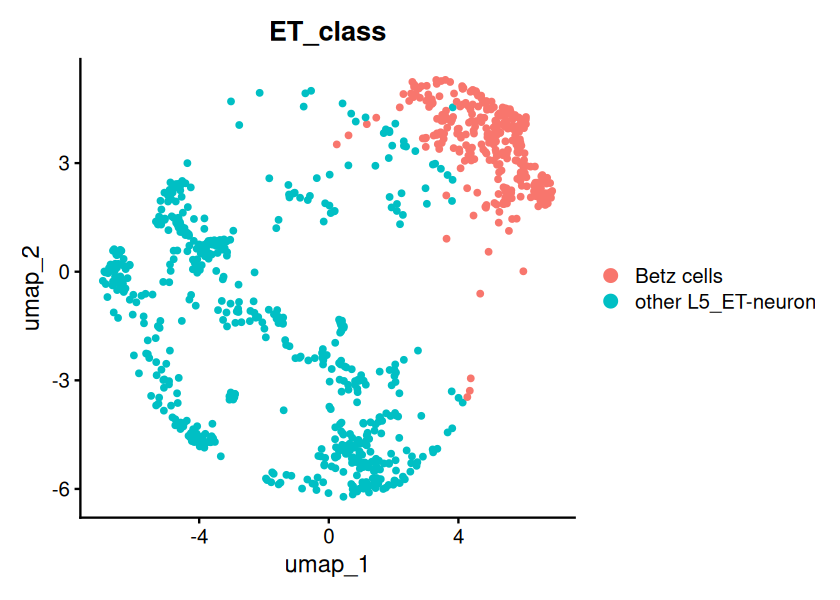

In [53]:
DimPlot(sub_atac, group.by = 'ET_class')

In [54]:
Idents(sub_atac) = 'ET_class'
da_peak = FindMarkers(sub_atac, ident.1 = "Betz cells", ident.2 = "other L5_ET-neuron", test.use = "LR",assay = 'peaks')



Warning message:
“glm.fit:拟合概率算出来是数值零或一”
Warning message:
“glm.fit:拟合概率算出来是数值零或一”


In [39]:
anno_df2 = anno_df1

anno_df2$annotation_clean <- sub(" \\(.*$", "", anno_df2$annotation)

In [ ]:
da_res_1 = subset(da_peak, p_val_adj < 0.05)

da_res_2 = da_res_1
da_res_2$peak <- rownames(da_res_2)


da_res_2 <- merge(da_res_2, links_df[, c("peak", "gene")], by = "peak", all.x = TRUE)
da_res_2 <- merge(da_res_2, anno_df1[, c("peak", "annotation")], by = "peak", all.x = TRUE)

da_res_2$annotation_clean <- sub(" \\(.*$", "", da_res_2$annotation)

da_res_2_1 = subset(da_res_2, gene != 'NA')
da_res_2_1 = da_res_2_1 %>% filter(!grepl("^ENSMFAG", gene))

da_res_2_up = subset(da_res_2_1, avg_log2FC > 0.5)
da_res_2_down = subset(da_res_2_1, avg_log2FC < -0.5)


In [30]:
top_peak = da_res_2_up %>% 
    filter(pct.1 > 0.2) %>%
    top_n(n = 20, wt = avg_log2FC)

top_peak

peak,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene,annotation
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
chr1-112668302-112669131,3.787338e-13,2.141029,0.209,0.040,2.648743e-07,SYT6,Distal Intergenic
chr12-126879247-126879918,3.127998e-14,2.049550,0.225,0.051,2.187621e-08,MLPH,Distal Intergenic
chr12-65644660-65646016,2.999868e-15,2.580277,0.201,0.027,2.098012e-09,MTX2,Distal Intergenic
chr13-17212514-17213549,4.341336e-16,1.995881,0.270,0.062,3.036191e-10,IL36B,3' UTR
chr13-17212514-17213549,4.341336e-16,1.995881,0.270,0.062,3.036191e-10,PSD4,3' UTR
chr13-17212514-17213549,4.341336e-16,1.995881,0.270,0.062,3.036191e-10,IL36RN,3' UTR
chr13-17212514-17213549,4.341336e-16,1.995881,0.270,0.062,3.036191e-10,IL1F10,3' UTR
chr13-82367594-82368922,3.660341e-12,1.992771,0.206,0.045,2.559925e-06,FOSL2,Distal Intergenic
chr13-82367594-82368922,3.660341e-12,1.992771,0.206,0.045,2.559925e-06,PLB1,Distal Intergenic


In [ ]:

write.csv(da_peak, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251223-new-all.csv')
# write.csv(da_peak, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251223-new-all.csv')
write.csv(da_res_2_1, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251223-new-subset.csv')

In [ ]:
da_peak = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251223-new-all.csv',row.names = 1)
da_peak

Warning message in file(file, "rt"):
“无法打开文件'/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251205-new-all.csv': 没有那个文件或目录”


ERROR: Error in file(file, "rt"): 无法打开链结


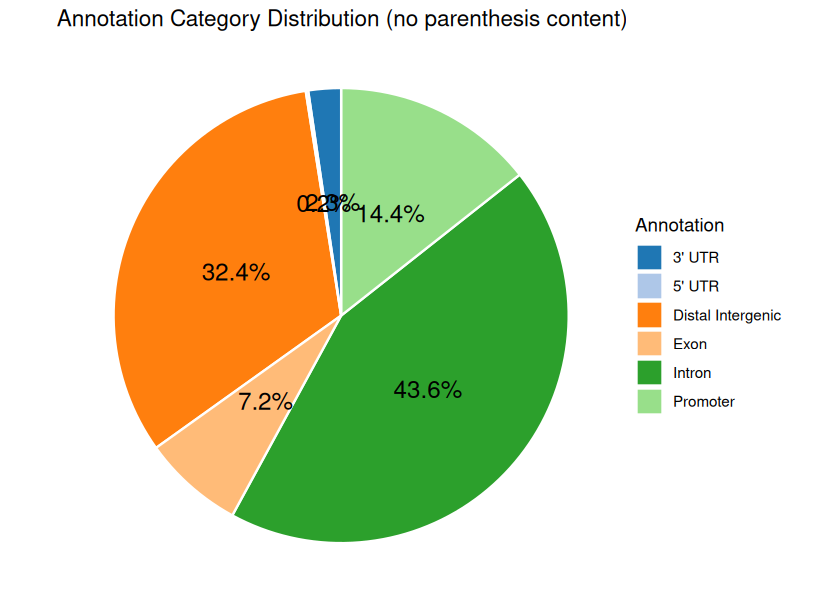

In [ ]:


da_res_2_up_use = da_res_2_up
# 去括号，仅保留括号前内容，确保NA不被转换为字符"NA"
da_res_2_up_use$annotation_clean <- sub(" \\(.*$", "", da_res_2_up_use$annotation)

# 统计各类别数量，确保排序（可选，优化Pie图顺序显示，有需要可修改排序方式）
annotation_count <- da_res_2_up_use %>%
  filter(!is.na(annotation_clean)) %>%
  count(annotation_clean, name = "Count") %>%
  arrange(desc(Count)) %>%
  mutate(Fraction = Count / sum(Count),
         PercentLabel = paste0(sprintf("%.1f", Fraction * 100), "%"),
         Annotation = annotation_clean)

# 颜色设置
tab20_colors <- c("#1f77b4","#aec7e8","#ff7f0e","#ffbb78","#2ca02c",
                  "#98df8a","#d62728","#ff9896","#9467bd","#c5b0d5",
                  "#8c564b","#c49c94","#e377c2","#f7b6d2","#7f7f7f",
                  "#c7c7c7","#bcbd22","#dbdb8d","#17becf","#9edae5")
num_ann <- nrow(annotation_count)
cur_colors <- tab20_colors[1:num_ann]

# Pie chart
p <- ggplot(annotation_count, aes(x = "", y = Count, fill = Annotation)) +
  geom_bar(width = 1, stat = "identity", color = "white") +
  coord_polar(theta = "y") +
  theme_void() +
  scale_fill_manual(values = cur_colors) +
  geom_text(aes(label = PercentLabel), 
            position = position_stack(vjust = 0.5), 
            color = "black", 
            size = 5) +
  ggtitle("Annotation Category Distribution (no parenthesis content)")

# 保存为pdf
ggsave("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_betz_snRNA/20251224_annotation_category_distribution.pdf", plot = p, width = 8, height = 6)
print(p)

In [ ]:
### RNA deg

deg_df = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_deg_res-20251118-new-subset.csv')
deg_df

X,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
ABHD3,2.059090e-47,2.0376347,0.522,0.106,4.311529e-43,ABHD3
PRKD1,8.398182e-44,0.8814948,0.808,0.382,1.758495e-39,PRKD1
KIAA0408,2.625506e-43,0.8370419,0.856,0.444,5.497546e-39,KIAA0408
RACGAP1,3.275539e-43,0.6392257,0.702,0.298,6.858651e-39,RACGAP1
SEZ6L,2.046005e-41,0.8057901,0.708,0.296,4.284130e-37,SEZ6L
ANXA5,4.675798e-40,2.3184984,0.412,0.066,9.790654e-36,ANXA5
ITGAV,2.202046e-39,0.7653697,0.748,0.342,4.610864e-35,ITGAV
DDHD1,1.099480e-38,0.7815310,0.830,0.436,2.302202e-34,DDHD1
PSME4,1.240327e-38,0.5467964,0.932,0.590,2.597120e-34,PSME4


In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4)

# 只展示chr6-94600446-94600984这个peak与CAST基因之间link的图并保存为pdf
peak_obj_1 = peak_obj
links <- Links(peak_obj_1)
# 只保留chr6-170173898-170174496和KCNIP1相关的连线
links_sub <- links[links$peak == "chr6-170173898-170174496" & links$gene == "KCNIP1", ]
# 创建一个只包含该link的新Links对象
Links(peak_obj_1) <- links_sub

pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251224coverageplot-peak-KCNIP1.pdf", width = 7, height = 4)
CoveragePlot(
    peak_obj_1,
    region = c('chr6-170173898-170174496'),
    # features = "KCNIP1",
    links = T,            # 展示link
    extend.upstream = 250000,
    extend.downstream = 50000,
    group.by = "ET_class",
    ncol = 1,
    assay = "peaks"
)
dev.off()
# chr1-112668302-112669131


In [ ]:
need_anno = c('Distal Intergenic','Intron')
grn_peak =  subset(df, gene %in% putative_target_genes)
show_peaks_list = grn_peak %>% 
filter(annotation_clean %in% need_anno) %>% 
filter(gene != 'SLIT1') %>% 
filter(gene != 'KCNIP1') %>% 
top_n(10, avg_log2FC) %>% 
arrange(desc(avg_log2FC)) %>% 
pull(peak)

options(repr.plot.width = 6, repr.plot.height = 12)

# 可视化该peak和CAST基因的link
CoveragePlot(
    peak_obj,
    region = show_peaks_list,
    links = F,            # 展示link
    extend.upstream = 1000,
    extend.downstream = 1000,
    group.by = "ET_class",
    ncol = 1,
    assay = "peaks",
    peaks = F,
    tile = FALSE,
    annotation = F,
)

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4)

# 只展示chr6-94600446-94600984这个peak与CAST基因之间link的图
# 假设已经有Links对象 links_obj 并且peak_obj是Seurat object
peak_obj_1 = peak_obj
# # 如果你已经有Links对象(比如用LinkPeaks生成)
# # 如果没有，可以根据需求加载你的Links对象，如 links <- Links(peak_obj)
links <- Links(peak_obj_1)
# 只保留chr6-94600446-94600984和CAST相关的连线
links_sub <- links[links$peak == "chr6-170173898-170174496" & links$gene == "KCNIP1", ]
# 创建一个只包含该link的新Links对象
Links(peak_obj_1) <- links_sub

# 可视化该peak和CAST基因的link
CoveragePlot(
    peak_obj_1,
    region = c('chr6-170173898-170174496'),
    # features = "KCNIP1",
    links = T,            # 展示link
    extend.upstream = 30000,
    extend.downstream = 30000,
    group.by = "ET_class",
    ncol = 1,
    assay = "peaks"
)